# Tuning model LatihIsyarat untuk domain kamera

Model yang sekarang dipakai aplikasi (`assets/models/model_float16.tflite`,
ensemble 3 seed, 5,27 MiB) sangat akurat di dataset tetapi tidak akurat di
kamera. Semua angka di bawah diukur dengan file model yang sekarang ada di
`assets/models/`:

| Evaluasi (transformasi di notebook ini) | Model sekarang |
| --- | --- |
| Sign-MNIST test resmi (7.172 gambar) | **99,30 %** |
| Test yang sama, dirender seperti crop kamera | **4,04 %** |
| 2.400 foto ASL nyata (split uji, 3 crop aplikasi) | **7,79 %** |
| Foto referensi kamus 28x28 (`assets/signs`) | 24/24 benar |

Penyebabnya domain data, bukan arsitektur. Isolasi faktor pada model yang
sama (satu transformasi per baris):

| Faktor | Akurasi model sekarang |
| --- | --- |
| 28x28 bersih | 99,3 % |
| Polaritas dibalik (tangan terang) | 30,7 % |
| Tangan mengecil ke 70 % frame | 57,1 % |
| Tangan mengecil ke 55 % frame | 13,3 % |
| Polaritas + tangan 55 % (seperti kamera) | **3,4 %** |
| Latar abu-abu 60 / 120 / 210 | 24,3 / 64,2 / 95,2 % |

Sign-MNIST berisi tangan **gelap** di latar **terang** yang memenuhi hampir
seluruh frame. Crop kamera aplikasi (`paddingScale` 1,60 dan 1,40) menghasilkan
tangan **terang** yang hanya menempati ~60 % frame dengan latar sembarang.

Notebook ini melatih ulang dengan:

1. **Augmentasi domain kamera** pada Sign-MNIST: polaritas acak, tangan
   diperkecil ke 55–100 % frame, latar acak dengan kontras dijamin, rotasi,
   shear, gamma, blur, noise.
2. **Foto ASL nyata** (10.873 foto, `Marxulia/asl_sign_languages_alphabets_v03`)
   yang di-crop dengan geometri yang sama seperti aplikasi.
3. Sebagian data bersih dipertahankan agar foto kamus dan jalur Foto/Upload
   tetap akurat.

Kontrak model tidak berubah, jadi hasilnya bisa langsung menggantikan file
lama:

```text
input   float32 [1, 28, 28, 1], luminance 0..255, rescaling 1/255 di dalam model
output  float32 [1, 24], softmax, urutan mengikuti assets/models/labels.json
```

Jalankan **Runtime > Change runtime type > T4 GPU**, lalu **Run all**.
Perkiraan waktu di T4: 15–25 menit.

## 1. Setup

Menyiapkan dependency, GPU, dan folder kerja. Kalau Drive di-mount, dataset dan
hasil disimpan di Drive supaya run berikutnya tidak mengunduh ulang.

Tanpa GPU, notebook otomatis menurunkan jumlah augmentasi dan epoch. Jangan
mengandalkan hasil run CPU untuk angka final.

In [ ]:
%pip install -q kagglehub pyarrow

import hashlib, io, json, shutil, time, urllib.request, zipfile
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

print("TensorFlow", tf.__version__)
GPUS = tf.config.list_physical_devices("GPU")
print("GPU:", GPUS if GPUS else "tidak ada (hasil CPU hanya untuk uji alur)")
for gpu in GPUS:
    tf.config.experimental.set_memory_growth(gpu, True)

CONFIG = dict(
    seed=42,
    samples_per_image=4,      # salinan augmentasi per baris Sign-MNIST
    real_crops=3,             # crop per foto nyata (tengah + context + tight)
    real_augmentations=2,     # salinan augmentasi per crop foto nyata
    real_test_per_class=100,  # foto uji per huruf (tidak pernah dilatih)
    batch_size=256,
    epochs=18,
    learning_rate=3e-3,
    weight_decay=1e-4,
    use_drive=True,
    drive_dir="/content/drive/MyDrive/LatihIsyarat",
)
if not GPUS:
    CONFIG["samples_per_image"] = 1
    CONFIG["epochs"] = 10
    print("Tanpa GPU: samples_per_image=1, epochs=10")

USE_DRIVE = CONFIG["use_drive"]
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except Exception as error:
        print("Drive tidak tersedia:", error)
        USE_DRIVE = False

FALLBACK_ROOT = Path("/content/latihisyarat") if Path("/content").is_dir() \
    else Path.cwd() / "latihisyarat"
ROOT = Path(CONFIG["drive_dir"]) if USE_DRIVE else FALLBACK_ROOT
DATA_DIR = ROOT / "data"
RUN_DIR = ROOT / "camera_robust_v1"
for folder in (DATA_DIR, RUN_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print("Folder kerja:", ROOT)

CLASS_NAMES = tuple("ABCDEFGHIKLMNOPQRSTUVWXY")   # J dan Z butuh gerakan
ORIGINAL_LABELS = tuple(i for i in range(26) if i not in (9, 25))
LABEL_INDEX = {label: index for index, label in enumerate(ORIGINAL_LABELS)}
MODEL_SIDE = 28

def download(url, target):
    target = Path(target)
    if target.exists() and target.stat().st_size > 0:
        return target
    print("mengunduh", url)
    partial = target.with_suffix(target.suffix + ".part")
    urllib.request.urlretrieve(url, partial)
    partial.replace(target)
    return target

TensorFlow 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mounted at /content/drive
Folder kerja: /content/drive/MyDrive/LatihIsyarat


## 2. Dataset Sign-MNIST

Diambil lewat `kagglehub`; kalau Kaggle meminta kredensial, dipakai mirror CSV
di GitHub dengan isi yang sama.

In [ ]:
def find_csvs(root):
    train = sorted(Path(root).rglob("sign_mnist_train.csv"))
    test = sorted(Path(root).rglob("sign_mnist_test.csv"))
    if not train or not test:
        raise FileNotFoundError("CSV Sign-MNIST tidak ditemukan di " + str(root))
    return train[0], test[0]

def fetch_sign_mnist(data_dir):
    data_dir = Path(data_dir)
    try:
        return find_csvs(data_dir)
    except FileNotFoundError:
        pass
    try:
        import kagglehub
        return find_csvs(kagglehub.dataset_download("datamunge/sign-language-mnist"))
    except Exception as error:
        print("kagglehub gagal, memakai mirror GitHub:", error)
        base = "https://raw.githubusercontent.com/gchilingaryan/Sign-Language/master"
        for name in ("sign_mnist_train.csv", "sign_mnist_test.csv"):
            download(f"{base}/{name}", data_dir / name)
        return find_csvs(data_dir)

def load_csv(path, limit=None):
    frame = pd.read_csv(path, nrows=limit)
    pixels = frame.iloc[:, 1:].to_numpy(np.uint8).reshape(-1, MODEL_SIDE, MODEL_SIDE)
    labels = np.array([LABEL_INDEX[int(v)] for v in frame.iloc[:, 0]], np.int16)
    return pixels, labels

train_csv, test_csv = fetch_sign_mnist(DATA_DIR)
X_clean, y_clean = load_csv(train_csv)
X_test, y_test = load_csv(test_csv)
print("Sign-MNIST train", X_clean.shape, "test", X_test.shape)
print("label per kelas train:", np.bincount(y_clean, minlength=24).min(),
      "-", np.bincount(y_clean, minlength=24).max())

Using Colab cache for faster access to the 'sign-language-mnist' dataset.
Sign-MNIST train (27455, 28, 28) test (7172, 28, 28)
label per kelas train: 957 - 1294


## 3. Foto ASL nyata

10.873 foto alfabet ASL dari Hugging Face: 100 foto per huruf dipakai sebagai
split uji (tidak pernah dilatih), sisanya untuk training. Foto berasal dari
webcam, jadi latar, cahaya, dan polaritasnya mirip kamera HP.

> Kartu dataset tidak mencantumkan lisensi. Pakai untuk eksperimen internal;
> sebelum distribusi publik, ganti dengan dataset berlisensi jelas atau foto
> tim sendiri.

In [ ]:
REAL_URL = ("https://huggingface.co/datasets/Marxulia/"
            "asl_sign_languages_alphabets_v03/resolve/main/"
            "data/train-00000-of-00001.parquet")
REAL_PARQUET = download(REAL_URL, DATA_DIR / "asl_real.parquet")

def load_real_photos(path, test_per_class, seed):
    import pyarrow.parquet as pq
    from PIL import Image

    handle = pq.ParquetFile(path)
    per_class = {index: [] for index in range(24)}
    for group in range(handle.metadata.num_row_groups):
        table = handle.read_row_group(group)
        for image_cell, label_cell in zip(table.column("image"),
                                          table.column("label")):
            label = label_cell.as_py()
            if label in LABEL_INDEX:
                per_class[LABEL_INDEX[label]].append(image_cell.as_py()["bytes"])

    rng = np.random.default_rng(seed)
    train, test = [], []
    for label, payloads in per_class.items():
        order = rng.permutation(len(payloads))
        test_rows = set(order[:test_per_class].tolist())
        for row, payload in enumerate(payloads):
            image = np.asarray(
                Image.open(io.BytesIO(payload)).convert("L"), np.float32
            )
            (test if row in test_rows else train).append((image, label))
    return train, test

REAL_TRAIN, REAL_TEST = load_real_photos(
    REAL_PARQUET, CONFIG["real_test_per_class"], CONFIG["seed"]
)
print("Foto nyata train", len(REAL_TRAIN), "test", len(REAL_TEST))

mengunduh https://huggingface.co/datasets/Marxulia/asl_sign_languages_alphabets_v03/resolve/main/data/train-00000-of-00001.parquet
Foto nyata train 7633 test 2400


## 4. Augmentasi domain kamera

Transformasi yang menghasilkan angka di tabel pembuka:

* latar diganti dengan level acak, kontras tangan–latar dijamin ≥ 45 level
  (latar yang kebetulan sama dengan warna kulit membuat siluet hilang);
* tangan diperkecil ke 55–100 % frame, meniru `paddingScale` aplikasi;
* polaritas dibalik pada 50 % sampel (tangan terang di latar gelap);
* rotasi ±20°, shear, translasi, gamma/kontras, blur, dan noise.

`camera_augment(..., camera_sim=True)` adalah versi deterministik untuk
mengukur akurasi domain kamera.

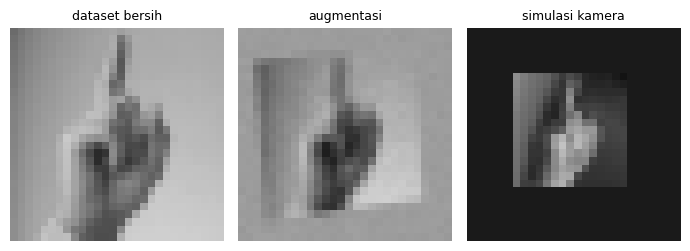

In [ ]:
def background_level(image):
    border = np.concatenate([image[0], image[-1], image[:, 0], image[:, -1]])
    return float(np.median(border))

def background_texture(rng, side, strength=10.0):
    coarse = rng.normal(0, strength, (side // 4 + 2, side // 4 + 2)).astype(np.float32)
    field = cv2.resize(coarse, (side, side), interpolation=cv2.INTER_CUBIC)
    yy, xx = np.mgrid[0:side, 0:side].astype(np.float32)
    ramp = (rng.uniform(-0.5, 0.5) * (xx / side - 0.5)
            + rng.uniform(-0.5, 0.5) * (yy / side - 0.5))
    return field + ramp * strength * 2.0

def camera_augment(rng, image28, camera_sim=False):
    '''Ubah 28x28 Sign-MNIST menjadi crop yang mirip keluaran kamera.'''
    img = image28.astype(np.float32)
    background = background_level(img)

    if camera_sim or rng.random() < 0.7:
        hand_pixels = img[np.abs(img - background) > 18]
        if hand_pixels.size < 30:
            hand_pixels = img.reshape(-1)
        hand_level = float(np.median(hand_pixels))
        delta = 90.0 if camera_sim else float(rng.uniform(45, 130))
        new_level = float(np.clip(
            hand_level + (delta if rng.random() < 0.5 else -delta), 10, 245
        ))
        near = np.clip(1.0 - np.abs(img - background) / 14.0, 0.0, 1.0)
        img = img * (1.0 - near) + (new_level + background_texture(rng, MODEL_SIDE)) * near
    else:
        new_level = background

    scale = 0.55 if camera_sim else float(rng.uniform(0.55, 1.0))
    side = max(6, int(round(MODEL_SIDE * scale)))
    inner = cv2.resize(img, (side, side), interpolation=cv2.INTER_AREA)
    canvas = np.full((MODEL_SIDE, MODEL_SIDE), new_level, np.float32)
    jitter = 0 if camera_sim else 1
    oy = (MODEL_SIDE - side) // 2 + int(rng.integers(-jitter, jitter + 1))
    ox = (MODEL_SIDE - side) // 2 + int(rng.integers(-jitter, jitter + 1))
    y0, x0 = max(0, oy), max(0, ox)
    y1, x1 = min(MODEL_SIDE, oy + side), min(MODEL_SIDE, ox + side)
    canvas[y0:y1, x0:x1] = inner[y0 - oy:y1 - oy, x0 - ox:x1 - ox]

    if not camera_sim:
        matrix = cv2.getRotationMatrix2D((14, 14), float(rng.uniform(-20, 20)), 1.0)
        matrix[0, 1] += rng.uniform(-0.10, 0.10)
        canvas = cv2.warpAffine(canvas, matrix, (MODEL_SIDE, MODEL_SIDE),
                                flags=cv2.INTER_LINEAR,
                                borderMode=cv2.BORDER_REFLECT)

    if camera_sim or rng.random() < 0.5:
        canvas = 255.0 - canvas
    if not camera_sim:
        gamma = float(rng.uniform(0.65, 1.5))
        canvas = 255.0 * np.clip(canvas, 0, 255) ** gamma / 255.0 ** gamma
        canvas = canvas * rng.uniform(0.75, 1.25) + rng.uniform(-20, 20)
        if rng.random() < 0.4:
            canvas = cv2.GaussianBlur(canvas, (0, 0), rng.uniform(0.3, 1.0))
        canvas = canvas + rng.normal(0, rng.uniform(0, 5), canvas.shape)
    return np.clip(canvas, 0, 255).astype(np.uint8)

rng = np.random.default_rng(CONFIG["seed"])
figure, axes = plt.subplots(1, 3, figsize=(7, 2.6))
samples = [("dataset bersih", X_clean[0]),
           ("augmentasi", camera_augment(rng, X_clean[0])),
           ("simulasi kamera", camera_augment(rng, X_clean[0], camera_sim=True))]
for axis, (title, sample) in zip(axes, samples):
    axis.imshow(sample, cmap="gray", vmin=0, vmax=255)
    axis.set_title(title, fontsize=9)
    axis.axis("off")
plt.tight_layout()
plt.show()

## 5. Data training dan evaluasi

Tiga set evaluasi memakai split uji yang tidak pernah dilatih:

1. `clean` — Sign-MNIST test apa adanya.
2. `camera_sim` — test yang sama setelah transformasi kamera.
3. `real_photos` — 2.400 foto nyata dengan tiga crop yang dipakai aplikasi
   (crop tengah untuk Foto/Upload, `paddingScale` 1,60 dan 1,40 untuk Video).

In [ ]:
def hand_box(image):
    '''Perkiraan kotak tangan seperti keluaran MediaPipe pada foto nyata.'''
    border = np.concatenate([image[0], image[-1], image[:, 0], image[:, -1]])
    background = float(np.median(border))
    mask = (np.abs(image - background) > max(18.0, 0.16 * abs(background))).astype(np.uint8)
    count, _, stats, _ = cv2.connectedComponentsWithStats(mask, 8)
    if count <= 1:
        return (0, 0, min(image.shape))
    largest = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
    x, y, width, height, _ = stats[largest]
    side = int(max(width, height))
    return (int(x + width // 2 - side // 2), int(y + height // 2 - side // 2), side)

def square_crop(image, box, padding, minimum_fraction=0.0, out=MODEL_SIDE):
    '''Sama dengan _squareCropAroundBounds + _sampleLuminanceCrop di Dart.'''
    height, width = image.shape
    x, y, box_side = box
    shortest, longest = min(width, height), max(width, height)
    minimum = float(np.clip(shortest * minimum_fraction, 1.0, shortest))
    side = float(np.clip(box_side * padding, minimum, longest))
    left = x + box_side / 2 - side / 2
    top = y + box_side / 2 - side / 2
    matrix = np.array([[out / side, 0, -left * out / side],
                       [0, out / side, -top * out / side]], np.float32)
    return cv2.warpAffine(image, matrix, (out, out), flags=cv2.INTER_AREA,
                          borderMode=cv2.BORDER_REPLICATE)

def center_crop(image, out=MODEL_SIDE):
    '''Sama dengan toModelImage(cropFraction: 1) untuk jalur Foto/Upload.'''
    shortest = min(image.shape)
    top = (image.shape[0] - shortest) // 2
    left = (image.shape[1] - shortest) // 2
    return cv2.resize(image[top:top + shortest, left:left + shortest],
                      (out, out), interpolation=cv2.INTER_AREA)

def real_photo_crops(image):
    crops = [center_crop(image)]
    box = hand_box(image)
    for padding, minimum in ((1.60, 0.28), (1.40, 0.22)):
        crops.append(square_crop(image, box, padding, minimum))
    return crops

def augment_real(rng, crop):
    '''Jitter fotometrik untuk crop foto nyata (ukuran sudah 28x28).'''
    result = crop.astype(np.float32)
    if rng.random() < 0.5:
        result = result[:, ::-1]
    if rng.random() < 0.5:
        matrix = cv2.getRotationMatrix2D(
            (14, 14), float(rng.uniform(-12, 12)), float(rng.uniform(0.92, 1.08))
        )
        result = cv2.warpAffine(result, matrix, (MODEL_SIDE, MODEL_SIDE),
                                flags=cv2.INTER_LINEAR,
                                borderMode=cv2.BORDER_REPLICATE)
    if rng.random() < 0.35:
        result = 255.0 - result
    gamma = float(rng.uniform(0.6, 1.7))
    result = 255.0 * np.clip(result, 0, 255) ** gamma / 255.0 ** gamma
    result = result * rng.uniform(0.6, 1.4) + rng.uniform(-40, 40)
    if rng.random() < 0.5:
        result = cv2.GaussianBlur(result, (0, 0), float(rng.uniform(0.3, 1.1)))
    if rng.random() < 0.3:
        result = result + rng.normal(0, float(rng.uniform(2, 9)), result.shape)
    return np.clip(result, 0, 255).astype(np.uint8)

CACHE = ROOT / "camera_train_set.npz"
if CACHE.exists():
    cached = np.load(CACHE)
    X_train, y_train = cached["x"], cached["y"]
    print("Memakai cache", CACHE, X_train.shape)
else:
    started = time.time()
    rng = np.random.default_rng(CONFIG["seed"])
    parts, part_labels = [], []
    for repeat in range(CONFIG["samples_per_image"]):
        parts.append(X_clean)
        part_labels.append(y_clean)
        parts.append(np.stack([camera_augment(rng, image) for image in X_clean]))
        part_labels.append(y_clean)
        print(f"  Sign-MNIST {repeat + 1}/{CONFIG['samples_per_image']}"
              f" ({time.time() - started:.0f}s)")

    for repeat in range(CONFIG["real_augmentations"]):
        rows, row_labels = [], []
        for image, label in REAL_TRAIN:
            for crop in real_photo_crops(image)[:CONFIG["real_crops"]]:
                rows.append(augment_real(rng, crop))
                row_labels.append(label)
        parts.append(np.stack(rows))
        part_labels.append(np.array(row_labels, np.int16))
        print(f"  foto nyata {repeat + 1}/{CONFIG['real_augmentations']}"
              f" ({time.time() - started:.0f}s)")

    X_train = np.concatenate(parts)
    y_train = np.concatenate(part_labels)
    order = rng.permutation(len(X_train))
    X_train, y_train = X_train[order], y_train[order]
    np.savez_compressed(CACHE, x=X_train, y=y_train)
    print("Training set", X_train.shape, "disimpan ke", CACHE)

print("label per kelas:", np.bincount(y_train, minlength=24).min(),
      "-", np.bincount(y_train, minlength=24).max())

EVAL = {
    "clean": (X_test, y_test),
    "camera_sim": (
        np.stack([camera_augment(np.random.default_rng(i), image, camera_sim=True)
                  for i, image in enumerate(X_test)]),
        y_test,
    ),
}
real_rows, real_labels = [], []
for image, label in REAL_TEST:
    for crop in real_photo_crops(image):
        real_rows.append(np.clip(crop, 0, 255).astype(np.uint8))
        real_labels.append(label)
EVAL["real_photos"] = (np.stack(real_rows), np.array(real_labels, np.int16))
for name, (rows, labels_) in EVAL.items():
    counts = np.bincount(labels_, minlength=24)
    print(f"{name:12s} {rows.shape} {counts.min()}-{counts.max()} per kelas")

Memakai cache /content/drive/MyDrive/LatihIsyarat/camera_train_set.npz (132719, 28, 28)
label per kelas: 4788 - 6136
clean        (7172, 28, 28) 144-498 per kelas
camera_sim   (7172, 28, 28) 144-498 per kelas
real_photos  (7200, 28, 28) 300-300 per kelas


## 6. Model

CNN ~160 ribu parameter (< 1 MiB setelah float16). Input tetap 0–255 dan
normalisasi tetap di dalam model, jadi `SignClassifier` di Flutter tidak perlu
diubah.

In [ ]:
def build_model(seed):
    tf.keras.utils.set_random_seed(seed)
    inputs = tf.keras.Input((MODEL_SIDE, MODEL_SIDE, 1), dtype="float32",
                            name="image_0_255")
    x = tf.keras.layers.Rescaling(1.0 / 255, name="rescale")(inputs)
    for index, filters in enumerate((32, 64, 128)):
        x = tf.keras.layers.Conv2D(filters, 3, padding="same", use_bias=False,
                                   name=f"conv{index}_a")(x)
        x = tf.keras.layers.BatchNormalization(name=f"bn{index}_a")(x)
        x = tf.keras.layers.Activation("relu", name=f"relu{index}_a")(x)
        if index < 2:
            x = tf.keras.layers.Conv2D(filters, 3, padding="same",
                                       use_bias=False, name=f"conv{index}_b")(x)
            x = tf.keras.layers.BatchNormalization(name=f"bn{index}_b")(x)
            x = tf.keras.layers.Activation("relu", name=f"relu{index}_b")(x)
        x = tf.keras.layers.MaxPooling2D(2, name=f"pool{index}")(x)
        x = tf.keras.layers.Dropout(0.10, name=f"drop{index}")(x)
    x = tf.keras.layers.GlobalAveragePooling2D(name="gap")(x)
    x = tf.keras.layers.Dense(128, activation="relu", name="dense")(x)
    x = tf.keras.layers.Dropout(0.30, name="drop_dense")(x)
    outputs = tf.keras.layers.Dense(24, activation="softmax",
                                    name="classifier")(x)
    return tf.keras.Model(inputs, outputs, name="asl24_camera_robust")

def evaluate_model(model, rows, labels_, batch=512):
    scores = model.predict(rows.astype(np.float32), batch_size=batch, verbose=0)
    predicted = scores.argmax(axis=1)
    per_class = {}
    for index, name in enumerate(CLASS_NAMES):
        mask = labels_ == index
        if mask.any():
            per_class[name] = float((predicted[mask] == labels_[mask]).mean())
    return {
        "accuracy": float((predicted == labels_).mean()),
        "mean_confidence": float(scores.max(axis=1).mean()),
        "per_class": per_class,
        "predicted": predicted,
    }

model = build_model(CONFIG["seed"])
model.summary()

Model: "asl24_camera_robust"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_0_255 (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv0_a (Conv2D)                │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn0_a (BatchNormalization)      │ (None, 28, 28, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu0_a (Activation)            │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv0_b (Conv2D)                │ (None, 28, 28, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn0_b (BatchNormalization)      │ (None, 28, 28, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu0_b (Activation)            │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool0 (MaxPooling2D)            │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop0 (Dropout)                 │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_a (Conv2D)                │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1_a (BatchNormalization)      │ (None, 14, 14, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1_a (Activation)            │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_b (Conv2D)                │ (None, 14, 14, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1_b (BatchNormalization)      │ (None, 14, 14, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1_b (Activation)            │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop1 (Dropout)                 │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_a (Conv2D)                │ (None, 7, 7, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2_a (BatchNormalization)      │ (None, 7, 7, 128)      │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2_a (Activation)            │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop2 (Dropout)                 │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,51

 Total params: 159,416 (622.72 KB)

 Trainable params: 158,776 (620.22 KB)

 Non-trainable params: 640 (2.50 KB)

## 7. Training

Setiap epoch mencetak akurasi ketiga domain, jadi kalau akurasi kamera tidak
naik, training bisa dihentikan. Log tersimpan di `deployment_metrics.json`.

In [ ]:
steps = max(1, len(X_train) // CONFIG["batch_size"])
schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=CONFIG["learning_rate"],
    decay_steps=steps * CONFIG["epochs"],
    alpha=0.02,
)
model.compile(
    optimizer=tf.keras.optimizers.AdamW(
        learning_rate=schedule, weight_decay=CONFIG["weight_decay"]
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

history_rows = []

class DeploymentMetrics(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        row = {"epoch": epoch + 1, "train_accuracy": float(logs["accuracy"])}
        for name, (rows, labels_) in EVAL.items():
            row[name] = evaluate_model(self.model, rows, labels_)["accuracy"]
        history_rows.append(row)
        (RUN_DIR / "deployment_metrics.json").write_text(
            json.dumps(history_rows, indent=2)
        )
        print("  " + "  ".join(f"{k}={v:.4f}" for k, v in row.items()))

train_dataset = (
    tf.data.Dataset.from_tensor_slices(
        (X_train.astype(np.float32), y_train.astype(np.int32))
    )
    .shuffle(min(len(X_train), 60_000), seed=CONFIG["seed"],
             reshuffle_each_iteration=True)
    .batch(CONFIG["batch_size"])
    .prefetch(tf.data.AUTOTUNE)
)

started = time.time()
model.fit(
    train_dataset,
    epochs=CONFIG["epochs"],
    callbacks=[
        tf.keras.callbacks.CSVLogger(str(RUN_DIR / "history.csv")),
        tf.keras.callbacks.TerminateOnNaN(),
        DeploymentMetrics(),
    ],
    verbose=1,
)
print(f"Training selesai dalam {(time.time() - started) / 60:.1f} menit")
model.save(str(RUN_DIR / "final.keras"))

Epoch 1/18
519/519 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.3394 - loss: 2.2179  epoch=1.0000  train_accuracy=0.5192  clean=0.8430  camera_sim=0.4642  real_photos=0.1297
519/519 ━━━━━━━━━━━━━━━━━━━━ 29s 36ms/step - accuracy: 0.5192 - loss: 1.6053
Epoch 2/18
517/519 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7229 - loss: 0.9295  epoch=2.0000  train_accuracy=0.7370  clean=0.9681  camera_sim=0.5538  real_photos=0.1751
519/519 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.7370 - loss: 0.8785
Epoch 3/18
517/519 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7702 - loss: 0.7671  epoch=3.0000  train_accuracy=0.7775  clean=0.9900  camera_sim=0.6907  real_photos=0.2206
519/519 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.7775 - loss: 0.7422
Epoch 4/18
517/519 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7950 - loss: 0.6747  epoch=4.0000  train_accuracy=0.7966  clean=0.9781  camera_sim=0.7221  real_photos=0.2085
519/519 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.7966

## 8. Evaluasi

Perbandingan langsung dengan model yang sekarang dipakai aplikasi.

clean        baru 0.9999 | lama 0.9930
camera_sim   baru 0.8677 | lama 0.0404
real_photos  baru 0.4426 | lama 0.0779

Kelas terlemah (real_photos):
  I: 0.123
  T: 0.190
  N: 0.243
  E: 0.267
  Q: 0.287
  K: 0.313


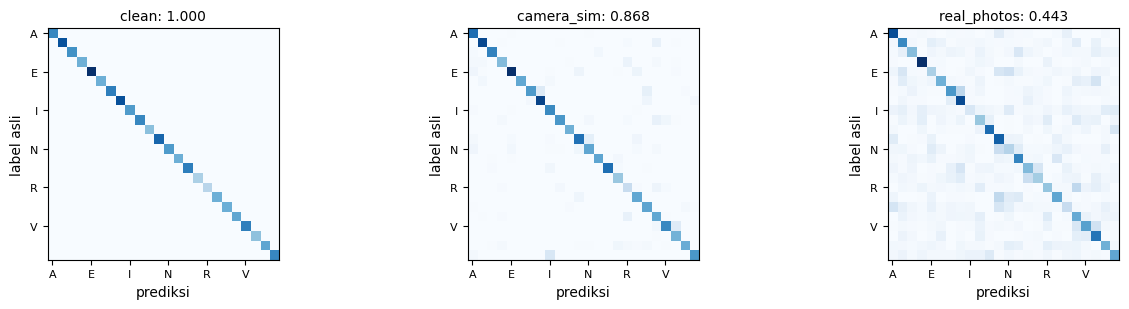

In [ ]:
BASELINE = {"clean": 0.9930, "camera_sim": 0.0404, "real_photos": 0.0779}
report = {}
for name, (rows, labels_) in EVAL.items():
    result = evaluate_model(model, rows, labels_)
    report[name] = {
        "accuracy": result["accuracy"],
        "mean_confidence": result["mean_confidence"],
        "per_class": result["per_class"],
    }
    print(f"{name:12s} baru {result['accuracy']:.4f} | lama {BASELINE[name]:.4f}")

print("\nKelas terlemah (real_photos):")
for label, value in sorted(report["real_photos"]["per_class"].items(),
                           key=lambda kv: kv[1])[:6]:
    print(f"  {label}: {value:.3f}")

figure, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for axis, name in zip(axes, EVAL):
    rows, labels_ = EVAL[name]
    predicted = evaluate_model(model, rows, labels_)["predicted"]
    confusion = np.zeros((24, 24), np.int64)
    np.add.at(confusion, (labels_, predicted), 1)
    axis.imshow(confusion, cmap="Blues")
    axis.set_title(f"{name}: {report[name]['accuracy']:.3f}", fontsize=10)
    axis.set_xlabel("prediksi")
    axis.set_ylabel("label asli")
    ticks = list(range(0, 24, 4))
    axis.set_xticks(ticks)
    axis.set_xticklabels([CLASS_NAMES[i] for i in ticks], fontsize=8)
    axis.set_yticks(ticks)
    axis.set_yticklabels([CLASS_NAMES[i] for i in ticks], fontsize=8)
plt.tight_layout()
plt.savefig(RUN_DIR / "confusion_matrices.png", dpi=140)
plt.show()

## 9. Ekspor TFLite float16

Kontrak input/output diperiksa ulang dan hasil TFLite dibandingkan dengan
prediksi Keras.

In [ ]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_types = [tf.float16]
payload = converter.convert()
TFLITE_PATH = RUN_DIR / "model_float16.tflite"
TFLITE_PATH.write_bytes(payload)
print(f"Ukuran TFLite: {len(payload) / 1024 / 1024:.3f} MiB")

interpreter = tf.lite.Interpreter(model_path=str(TFLITE_PATH))
interpreter.allocate_tensors()
input_detail = interpreter.get_input_details()[0]
output_detail = interpreter.get_output_details()[0]
print("input", input_detail["shape"], input_detail["dtype"])
print("output", output_detail["shape"], output_detail["dtype"])
assert list(input_detail["shape"]) == [1, MODEL_SIDE, MODEL_SIDE, 1]
assert list(output_detail["shape"]) == [1, 24]

sample_rows, sample_labels = EVAL["camera_sim"]
sample_rows = sample_rows[:512].astype(np.float32)
keras_scores = model.predict(sample_rows, batch_size=256, verbose=0)
tflite_scores = np.empty_like(keras_scores)
for row in range(len(sample_rows)):
    interpreter.set_tensor(
        input_detail["index"], sample_rows[row:row + 1].reshape(1, 28, 28, 1)
    )
    interpreter.invoke()
    tflite_scores[row] = interpreter.get_tensor(output_detail["index"])[0]
agreement = float((keras_scores.argmax(1) == tflite_scores.argmax(1)).mean())
max_difference = float(np.abs(keras_scores - tflite_scores).max())
tflite_accuracy = float((tflite_scores.argmax(1) == sample_labels[:512]).mean())
print(f"Kesesuaian label Keras vs TFLite: {agreement:.4f}")
print(f"Selisih skor maksimum: {max_difference:.6f}")
print(f"Akurasi TFLite pada 512 sampel kamera: {tflite_accuracy:.4f}")
assert agreement >= 0.99 and max_difference < 0.05

Saved artifact at '/tmp/tmp0gif43ul'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name='image_0_255')
Output Type:
  TensorSpec(shape=(None, 24), dtype=tf.float32, name=None)
Captures:
  136386696313360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136386693556432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136386693556240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136386693555856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136386693547408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136386693560272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136386693558160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136386693560080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136386693546064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136386693557584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136386691895888:

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Kesesuaian label Keras vs TFLite: 1.0000
Selisih skor maksimum: 0.002786
Akurasi TFLite pada 512 sampel kamera: 0.8516


In [ ]:
labels_payload = {
    "schema_version": 1,
    "labels": list(CLASS_NAMES),
    "output_index_to_label": {str(i): label for i, label in enumerate(CLASS_NAMES)},
    "unsupported_dynamic_letters": ["J", "Z"],
}
(RUN_DIR / "labels.json").write_text(json.dumps(labels_payload, indent=2) + "\n")

metadata = {
    "schema_version": 1,
    "model_name": "LatihIsyarat - camera-domain robust",
    "model_version": "camera_robust_v1",
    "input_contract": {
        "shape": [1, 28, 28, 1],
        "dtype": "float32",
        "value_range_before_model": [0.0, 255.0],
        "color_space": "grayscale",
        "normalization": "Rescaling(1/255) inside the model",
        "mobile_must_divide_by_255": False,
    },
    "output_contract": {
        "shape": [1, 24],
        "dtype": "float32",
        "labels": list(CLASS_NAMES),
    },
    "training_data": {
        "sign_mnist_rows": int(len(X_clean)),
        "augmented_sign_mnist_rows": int(len(X_clean) * CONFIG["samples_per_image"]),
        "real_photos_train": int(len(REAL_TRAIN)),
        "real_photos_test": int(len(REAL_TEST)),
        "total_rows": int(len(X_train)),
        "augmentation": "polarity flip, 55-100% hand scale, random background "
                        "with guaranteed contrast, rotation/shear, gamma, blur, noise",
    },
    "metrics": {name: {"accuracy": value["accuracy"],
                       "mean_confidence": value["mean_confidence"]}
                for name, value in report.items()},
    "tflite": {
        "path": "model_float16.tflite",
        "quantization": "float16_weights",
        "size_bytes": len(payload),
        "sha256": hashlib.sha256(payload).hexdigest(),
        "keras_tflite_label_agreement": agreement,
        "maximum_absolute_score_difference": max_difference,
    },
    "camera_warning": "Angka real_photos adalah foto webcam, bukan kamera HP. "
                      "Ukur ulang di HP sebelum menyimpulkan akurasi.",
}
(RUN_DIR / "model_metadata.json").write_text(json.dumps(metadata, indent=2) + "\n")
(RUN_DIR / "report.json").write_text(json.dumps(report, indent=2) + "\n")
print(json.dumps({k: round(v["accuracy"], 4) for k, v in report.items()}, indent=2))
print("SHA-256:", metadata["tflite"]["sha256"])

bundle = Path("/content/latihisyarat_model_camera_robust.zip")
with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED) as archive:
    for name in ("model_float16.tflite", "labels.json", "model_metadata.json",
                 "report.json", "history.csv", "deployment_metrics.json",
                 "confusion_matrices.png"):
        path = RUN_DIR / name
        if path.exists():
            archive.write(path, name)
print("Bundle:", bundle, f"{bundle.stat().st_size / 1024 / 1024:.2f} MiB")

try:
    from google.colab import files
    files.download(str(bundle))
except Exception as error:
    print("Unduh manual dari", bundle, "(", error, ")")

{
  "clean": 0.9999,
  "camera_sim": 0.8677,
  "real_photos": 0.4426
}
SHA-256: 74f52ab0d6f091b37600ce65c4b7797a102c6e26112b6c2e4824483b168140bc
Bundle: /content/latihisyarat_model_camera_robust.zip 0.31 MiB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Memasang hasil di aplikasi Flutter

1. Unduh `latihisyarat_model_camera_robust.zip`, ekstrak.
2. Ganti `assets/models/model_float16.tflite`, `labels.json`, dan
   `model_metadata.json` dengan file dari zip.
3. `flutter clean && flutter pub get && flutter test`
4. Uji di HP (`flutter run`) pada mode Video, Foto, dan Upload.

Catatan tuning:

* Ambang keyakinan aplikasi tetap 60 % (`_minimumConfidence`). Model ini
  dilatih dengan label lebih jujur, jadi keyakinan < 60 % kini biasanya
  berarti pose memang ambigu.
* Akurasi kamera masih kurang? Naikkan `samples_per_image` ke 3–4 atau
  `real_augmentations` ke 2, lalu hapus `camera_train_set.npz` di Drive dan
  jalankan ulang.
* Foto kamus (`assets/signs`) jadi salah? Naikkan porsi data bersih: tambahkan
  `parts.append(X_clean)` sekali lagi, atau sempitkan skala augmentasi ke
  0,7–1,0.
* Angka `real_photos` berasal dari foto webcam, bukan kamera HP. Validasi
  akhir tetap diukur di HP mengikuti `CAMERA_VALIDATION.md`.